# Лабораторная работа №2
## Продвинутая инженерия признаков и отбор

**Вариант:** 10  
**Датасет:** Iris  
**Задача:** многоклассовая классификация  
**Импутация:** SimpleImputer, KNNImputer, IterativeImputer  
**Выбросы:** осторожное исследование LOF  
**Отбор признаков:** RFE и L1-регуляризация

## 1. Окружение и воспроизводимость

In [1]:
from pathlib import Path
import json
import platform
import subprocess
import sys
import warnings

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
    classification_report, confusion_matrix, f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, label_binarize

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (PROJECT_ROOT / ".git").exists():
    raise RuntimeError("Запустите Notebook из корня репозитория или папки notebooks.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "lab2"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "lab2"
FIGURE_DIR = REPORT_DIR / "figures"
for directory in (RAW_DIR, PROCESSED_DIR, MODEL_DIR, REPORT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Корень проекта: {PROJECT_ROOT}")
print(f"Python: {platform.python_version()}")
print(f"Ветка Git: {subprocess.run(['git','branch','--show-current'], cwd=PROJECT_ROOT, capture_output=True, text=True).stdout.strip()}")

Корень проекта: C:\Users\Доктор Варвар\Desktop\все\MWwithD
Python: 3.11.9
Ветка Git: fix/all-labs-requirements


## 2. Подготовка данных и искусственных пропусков

В Iris нет пропусков. Согласно заданию лабораторной №2 создаётся 15%
пропусков в трёх числовых колонках по механизму **MCAR** (Missing Completely
At Random): позиции выбираются генератором случайных чисел независимо от
значений признаков и целевого класса. MCAR выбран, чтобы сравнение импутеров
измеряло именно качество восстановления, а не влияние скрытого правила MAR.
Сначала формируется отложенный test, затем
только в train добавляются четыре контролируемых выброса: LOF не получает
возможность влиять на тестовую выборку.

In [2]:
iris = load_iris(as_frame=True)
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
df = iris.data.copy()
df.columns = features
df["target"] = iris.target.astype(int)

rng = np.random.default_rng(RANDOM_STATE)
missing_columns = ["sepal_length", "sepal_width", "petal_length"]
n_missing = int(round(len(df) * 0.15))
df_missing = df.copy()
for column in missing_columns:
    indices = rng.choice(df_missing.index, size=n_missing, replace=False)
    df_missing.loc[indices, column] = np.nan

raw_path = RAW_DIR / "iris_lab2.csv"
df_missing.to_csv(raw_path, index=False)

X = df_missing[features]
y = df_missing["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

# Добавляем выбросы только в train, сохраняя исходные индексы и классы.
X_train = X_train.copy()
outlier_indices = X_train.dropna().sample(n=4, random_state=RANDOM_STATE).index
X_train.loc[outlier_indices, "sepal_length"] *= 2.8
X_train.loc[outlier_indices, "sepal_width"] *= 0.25

train_df = X_train.copy(); train_df["target"] = y_train
test_df = X_test.copy(); test_df["target"] = y_test
train_path = PROCESSED_DIR / "train.csv"
test_path = PROCESSED_DIR / "test.csv"
train_df.to_csv(train_path, index=False); test_df.to_csv(test_path, index=False)

missing_summary = pd.DataFrame({
    "count": df_missing.isna().sum(),
    "percent": (df_missing.isna().mean() * 100).round(2),
})
display(df.head())
display(missing_summary)
print(f"Train: {train_df.shape}; test: {test_df.shape}")
print(f"Контролируемые выбросы в train: {list(map(int, outlier_indices))}")
assert df_missing[missing_columns].isna().sum().eq(n_missing).all()

,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


,count,percent
sepal_length,22,14.67
sepal_width,22,14.67
petal_length,22,14.67
petal_width,0,0.00
target,0,0.00


Train: (120, 5); test: (30, 5)
Контролируемые выбросы в train: [41, 106, 0, 31]


## 3. Визуализация пропусков и исходных распределений

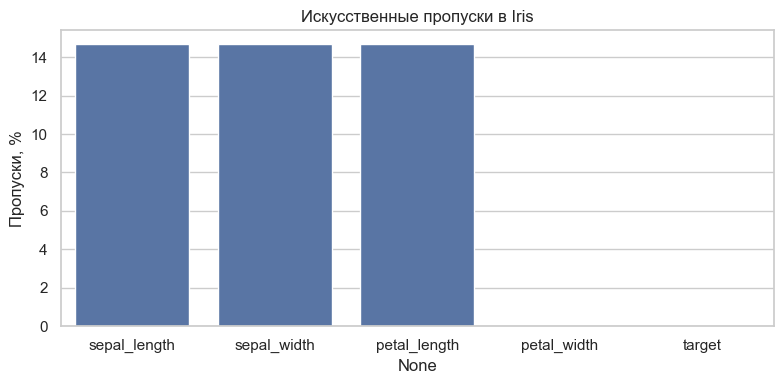

Сохранено: reports\lab2\figures\missing_values.png


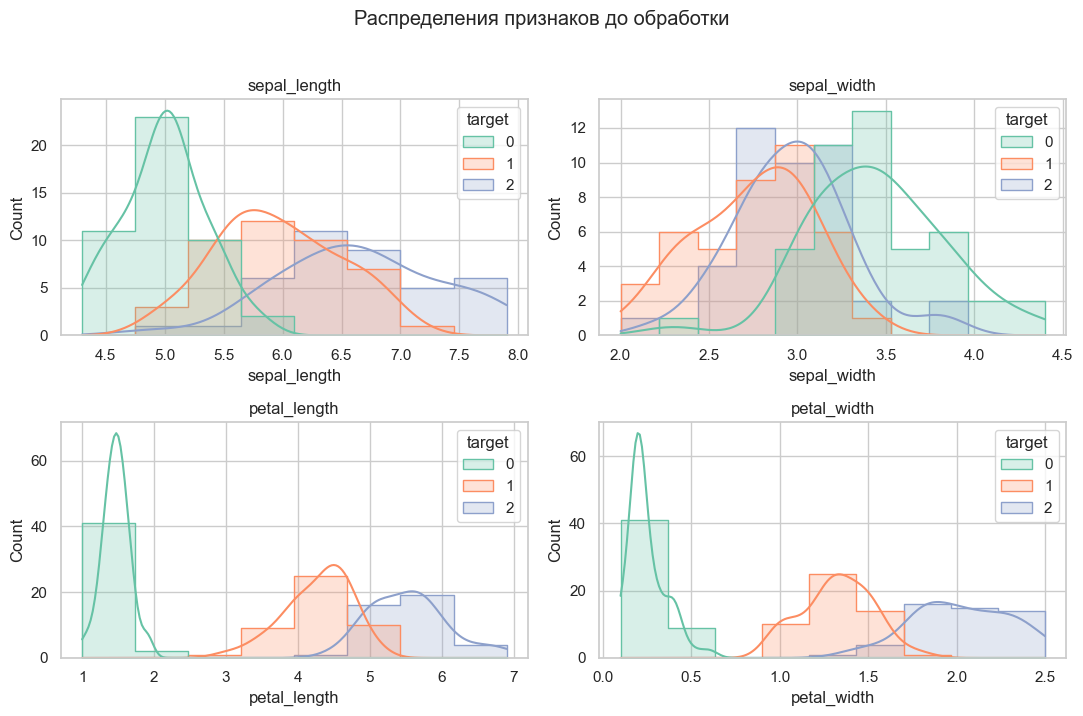

Сохранено: reports\lab2\figures\initial_distributions.png


In [3]:
def save_figure(name):
    path = FIGURE_DIR / name
    plt.tight_layout(); plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show(); plt.close()
    print(f"Сохранено: {path.relative_to(PROJECT_ROOT)}")

plt.figure(figsize=(8, 4))
sns.barplot(x=missing_summary.index, y=missing_summary["percent"], color="#4C72B0")
plt.title("Искусственные пропуски в Iris"); plt.ylabel("Пропуски, %")
save_figure("missing_values.png")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for feature, ax in zip(features, axes.flat):
    sns.histplot(data=df_missing, x=feature, hue="target", kde=True, ax=ax,
                 palette="Set2", element="step")
    ax.set_title(feature)
fig.suptitle("Распределения признаков до обработки", y=1.02)
save_figure("initial_distributions.png")

## 4. Сравнение трёх методов импутации

Масштабирование выполняется перед импутацией, как указано в примечаниях к
лабораторной работе. StandardScaler сохраняет NaN, после чего импутер их
заполняет. Каждый Pipeline оценивается пятифолдовой стратифицированной CV.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc_ovr", "accuracy": "accuracy", "f1": "f1_macro"}
imputers = {
    "Simple (median)": SimpleImputer(strategy="median"),
    "KNN": KNNImputer(n_neighbors=5, weights="distance"),
    "Iterative": IterativeImputer(max_iter=20, random_state=RANDOM_STATE),
}

imputation_rows = []
for name, imputer in imputers.items():
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", imputer),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    ])
    scores = cross_validate(candidate, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    imputation_rows.append({
        "method": name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "accuracy_mean": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "f1_macro_mean": scores["test_f1"].mean(),
        "f1_macro_std": scores["test_f1"].std(),
    })

imputation_results = pd.DataFrame(imputation_rows).sort_values(
    ["roc_auc_mean", "accuracy_mean"], ascending=[False, False])
imputation_results.to_csv(REPORT_DIR / "imputation_comparison.csv", index=False)
display(imputation_results)
best_imputer_name = imputation_results.iloc[0]["method"]
best_imputer = imputers[best_imputer_name]
print(f"Лучший импутер по ROC-AUC: {best_imputer_name}")

,method,roc_auc_mean,roc_auc_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std
1,KNN,0.995833,0.008333,0.975,0.020412,0.974902,0.020492
2,Iterative,0.995833,0.008333,0.975,0.020412,0.974902,0.020492
0,Simple (median),0.995833,0.008333,0.950,0.031180,0.950040,0.031066


Лучший импутер по ROC-AUC: KNN


## 5. Распределения заполненных значений

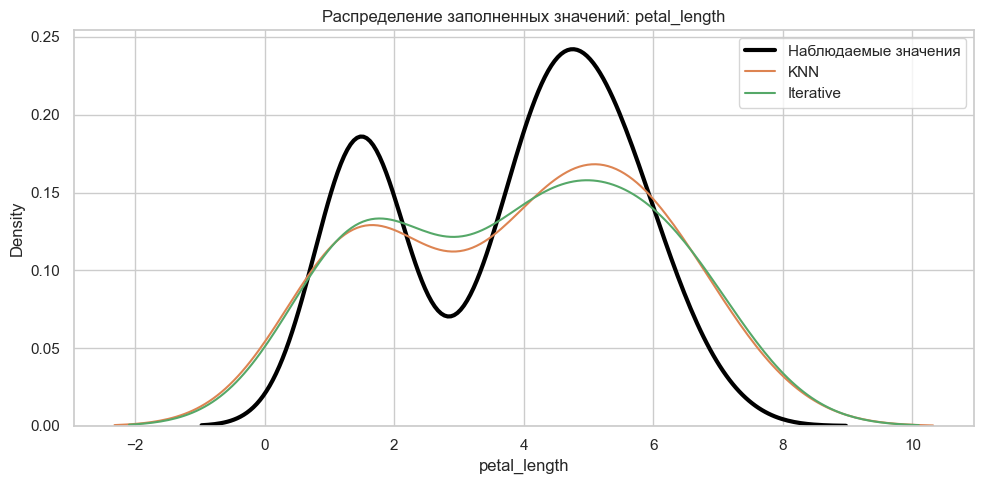

Сохранено: reports\lab2\figures\imputation_distributions.png


In [5]:
comparison_feature = "petal_length"
observed = X_train[comparison_feature].dropna()
imputed_frames = []
for name, imputer in imputers.items():
    scaler = StandardScaler()
    scaled = scaler.fit_transform(X_train)
    filled_scaled = imputer.fit_transform(scaled)
    filled = scaler.inverse_transform(filled_scaled)
    frame = pd.DataFrame(filled, columns=features, index=X_train.index)
    imputed_frames.append(pd.DataFrame({
        "value": frame.loc[X_train[comparison_feature].isna(), comparison_feature],
        "method": name,
    }))

plt.figure(figsize=(10, 5))
sns.kdeplot(observed, label="Наблюдаемые значения", linewidth=3, color="black")
for frame in imputed_frames:
    sns.kdeplot(data=frame, x="value", label=frame["method"].iloc[0], warn_singular=False)
plt.title(f"Распределение заполненных значений: {comparison_feature}")
plt.legend()
save_figure("imputation_distributions.png")

## 6. Кастомное удаление выбросов LOF только из train

Класс реализует `fit_resample`, поэтому imblearn Pipeline применяет его только
при обучении. При predict тестовая выборка не фильтруется.

,method,roc_auc_mean,roc_auc_std,accuracy_mean,f1_macro_mean
0,Без LOF,0.995833,0.008333,0.975000,0.974902
1,LOF только train,0.965104,0.030082,0.941667,0.941786


LOF включается в финальную модель: False


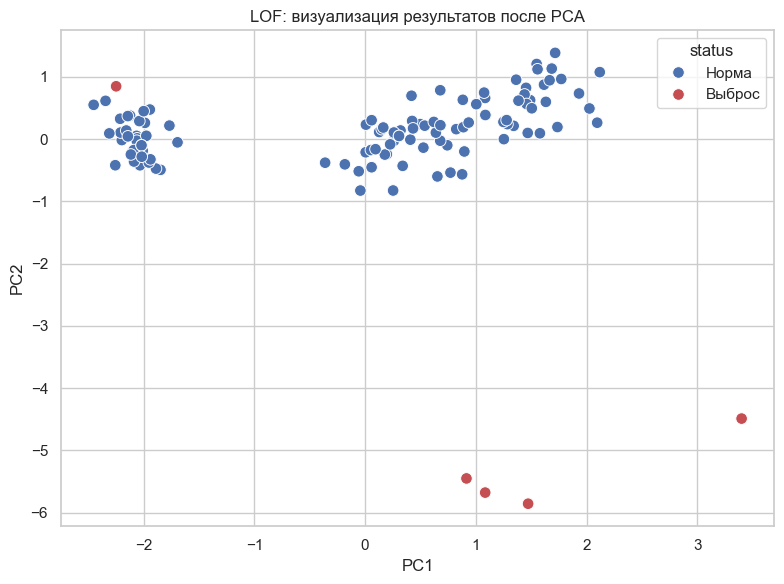

Сохранено: reports\lab2\figures\lof_pca.png


In [6]:
class LOFTrainSampler(BaseEstimator):
    """Удаляет найденные LOF выбросы только при fit_resample."""
    def __init__(self, n_neighbors=20, contamination=0.035):
        self.n_neighbors = n_neighbors
        self.contamination = contamination

    def fit_resample(self, X, y):
        neighbors = min(self.n_neighbors, max(2, len(X) - 1))
        self.detector_ = LocalOutlierFactor(
            n_neighbors=neighbors, contamination=self.contamination)
        labels = self.detector_.fit_predict(X)
        self.inlier_mask_ = labels == 1
        self.n_removed_ = int((~self.inlier_mask_).sum())
        y_array = np.asarray(y)
        return X[self.inlier_mask_], y_array[self.inlier_mask_]

base_steps = [
    ("scaler", StandardScaler()),
    ("imputer", best_imputer),
]
without_lof = Pipeline(base_steps + [
    ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))])
with_lof = ImbPipeline(base_steps + [
    ("lof", LOFTrainSampler()),
    ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))])

lof_rows = []
for name, candidate in {"Без LOF": without_lof, "LOF только train": with_lof}.items():
    scores = cross_validate(candidate, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    lof_rows.append({
        "method": name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "accuracy_mean": scores["test_accuracy"].mean(),
        "f1_macro_mean": scores["test_f1"].mean(),
    })
lof_results = pd.DataFrame(lof_rows).sort_values("roc_auc_mean", ascending=False)
lof_results.to_csv(REPORT_DIR / "lof_comparison.csv", index=False)
display(lof_results)
use_lof = lof_results.iloc[0]["method"] == "LOF только train"
print(f"LOF включается в финальную модель: {use_lof}")

# Визуализация LOF после масштабирования и импутации.
scaler_vis = StandardScaler(); train_scaled = scaler_vis.fit_transform(X_train)
train_filled = best_imputer.fit_transform(train_scaled)
lof_vis = LocalOutlierFactor(n_neighbors=20, contamination=0.035)
lof_labels = lof_vis.fit_predict(train_filled)
pca_points = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(train_filled)
pca_df = pd.DataFrame({"PC1": pca_points[:, 0], "PC2": pca_points[:, 1],
                       "status": np.where(lof_labels == -1, "Выброс", "Норма")})
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="status",
                palette={"Норма": "#4C72B0", "Выброс": "#C44E52"}, s=70)
plt.title("LOF: визуализация результатов после PCA")
save_figure("lof_pca.png")

## 7. Генерация и отбор признаков

PolynomialFeatures создаёт квадраты и взаимодействия. Сравниваются отсутствие
отбора, RFE и встроенный L1-отбор (классификационный аналог Lasso).

In [7]:
poly = PolynomialFeatures(degree=2, include_bias=False)
poly.fit(np.zeros((1, len(features))))
polynomial_names = poly.get_feature_names_out(features)
print(f"Признаков до PolynomialFeatures: {len(features)}")
print(f"Признаков после PolynomialFeatures: {len(polynomial_names)}")

selectors = {
    "Без отбора": "passthrough",
    "RFE": RFE(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
               n_features_to_select=8, step=1),
    "L1": SelectFromModel(LogisticRegression(
        penalty="l1", solver="liblinear", C=0.5, max_iter=3000,
        random_state=RANDOM_STATE), threshold="median"),
}

selection_rows = []
for name, selector in selectors.items():
    steps = base_steps.copy()
    if use_lof:
        steps.append(("lof", LOFTrainSampler()))
    steps.extend([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("selector", selector),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    ])
    candidate = ImbPipeline(steps) if use_lof else Pipeline(steps)
    scores = cross_validate(candidate, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    selection_rows.append({
        "method": name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "accuracy_mean": scores["test_accuracy"].mean(),
        "f1_macro_mean": scores["test_f1"].mean(),
    })

selection_results = pd.DataFrame(selection_rows).sort_values("roc_auc_mean", ascending=False)
selection_results.to_csv(REPORT_DIR / "feature_selection_comparison.csv", index=False)
display(selection_results)
best_selector_name = selection_results.iloc[0]["method"]
best_selector = selectors[best_selector_name]
print(f"Лучший вариант отбора: {best_selector_name}")

Признаков до PolynomialFeatures: 4
Признаков после PolynomialFeatures: 14


,method,roc_auc_mean,roc_auc_std,accuracy_mean,f1_macro_mean
1,RFE,0.998958,0.002083,0.975000,0.974902
0,Без отбора,0.983333,0.024296,0.966667,0.966536
2,L1,0.983333,0.024296,0.958333,0.957971


Лучший вариант отбора: RFE


## 8. Финальный Pipeline и GridSearchCV

In [8]:
final_steps = base_steps.copy()
if use_lof:
    final_steps.append(("lof", LOFTrainSampler()))
final_steps.extend([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("selector", best_selector),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])
final_pipeline = ImbPipeline(final_steps) if use_lof else Pipeline(final_steps)

param_grid = {"model__C": [0.1, 1.0, 10.0, 100.0]}
if use_lof:
    param_grid["lof__contamination"] = [0.025, 0.035, 0.05]

grid_search = GridSearchCV(final_pipeline, param_grid, scoring="roc_auc_ovr",
                           cv=cv, n_jobs=-1, return_train_score=True)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
grid_results = pd.DataFrame(grid_search.cv_results_).sort_values("rank_test_score")
grid_results.to_csv(REPORT_DIR / "grid_search_results.csv", index=False)
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучшая CV ROC-AUC: {grid_search.best_score_:.4f}")
display(grid_results[["params", "mean_train_score", "mean_test_score",
                      "std_test_score", "rank_test_score"]].head(10))

# Список выбранных признаков финальной модели.
if best_selector_name == "Без отбора":
    selected_mask = np.ones(len(polynomial_names), dtype=bool)
else:
    selected_mask = best_model.named_steps["selector"].get_support()
selected_features = pd.DataFrame({
    "feature": polynomial_names,
    "selected": selected_mask,
})
selected_features.to_csv(REPORT_DIR / "selected_features.csv", index=False)
display(selected_features[selected_features["selected"]])

Лучшие параметры: {'model__C': 1.0}
Лучшая CV ROC-AUC: 0.9990


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
1,{'model__C': 1.0},0.998568,0.998958,0.002083,1
2,{'model__C': 10.0},0.998828,0.998958,0.002083,1
3,{'model__C': 100.0},0.999023,0.997396,0.005208,3
0,{'model__C': 0.1},0.998242,0.995833,0.008333,4


,feature,selected
0,sepal_length,True
1,sepal_width,True
2,petal_length,True
3,petal_width,True
10,sepal_width petal_width,True
11,petal_length^2,True
12,petal_length petal_width,True
13,petal_width^2,True


## 9. Финальная оценка на отложенном test

{
  "variant": 10,
  "dataset": "Iris",
  "best_imputer": "KNN",
  "use_lof": false,
  "best_selector": "RFE",
  "best_params": {
    "model__C": 1.0
  },
  "cv_roc_auc": 0.998958,
  "test_accuracy": 0.966667,
  "test_f1_macro": 0.966583,
  "test_roc_auc_macro_ovr": 0.993333
}


,precision,recall,f1-score,support
setosa,1.000000,1.000000,1.000000,10.000000
versicolor,1.000000,0.900000,0.947368,10.000000
virginica,0.909091,1.000000,0.952381,10.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.969697,0.966667,0.966583,30.000000
weighted avg,0.969697,0.966667,0.966583,30.000000


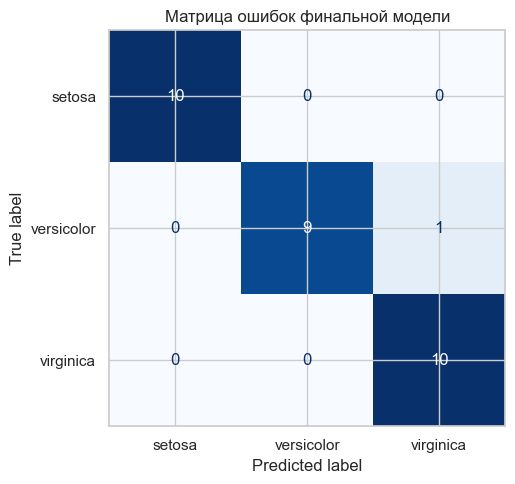

Сохранено: reports\lab2\figures\confusion_matrix.png


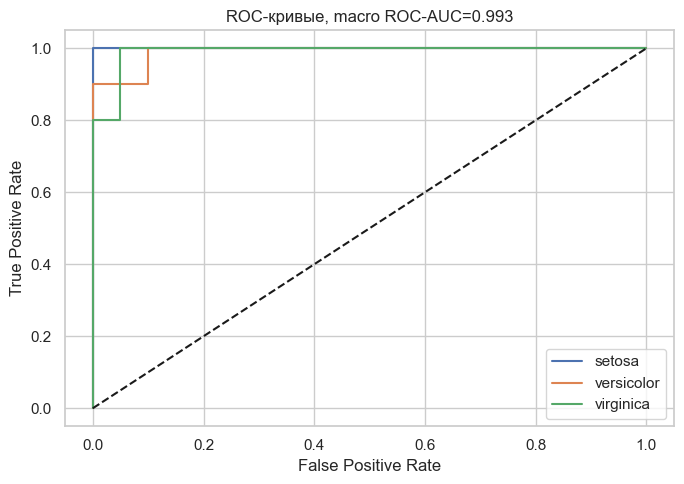

Сохранено: reports\lab2\figures\roc_curves.png


In [9]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
cm = confusion_matrix(y_test, y_pred)

metrics = {
    "variant": 10,
    "dataset": "Iris",
    "best_imputer": best_imputer_name,
    "use_lof": bool(use_lof),
    "best_selector": best_selector_name,
    "best_params": grid_search.best_params_,
    "cv_roc_auc": round(float(grid_search.best_score_), 6),
    "test_accuracy": round(float(accuracy), 6),
    "test_f1_macro": round(float(f1_macro), 6),
    "test_roc_auc_macro_ovr": round(float(roc_auc), 6),
}
(REPORT_DIR / "model_metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(metrics, ensure_ascii=False, indent=2))

class_report = pd.DataFrame(classification_report(
    y_test, y_pred, target_names=iris.target_names, output_dict=True,
    zero_division=0)).T
class_report.to_csv(REPORT_DIR / "classification_report.csv")
display(class_report)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Матрица ошибок финальной модели")
save_figure("confusion_matrix.png")

y_binary = label_binarize(y_test, classes=np.arange(3))
plt.figure(figsize=(7, 5))
for i, name in enumerate(iris.target_names):
    fpr, tpr, _ = roc_curve(y_binary[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.title(f"ROC-кривые, macro ROC-AUC={roc_auc:.3f}")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.legend()
save_figure("roc_curves.png")

## 10. Сохранение модели, DVC и аналитический отчёт

In [10]:
model_path = MODEL_DIR / "iris_lab2_pipeline.pkl"
with model_path.open("wb") as file:
    cloudpickle.dump(best_model, file)
with model_path.open("rb") as file:
    loaded_model = cloudpickle.load(file)
assert np.array_equal(y_pred, loaded_model.predict(X_test))

def run_command(command):
    result = subprocess.run(command, cwd=PROJECT_ROOT, capture_output=True,
                            text=True, encoding="utf-8", errors="replace")
    print(f"$ {' '.join(map(str, command))}")
    if result.stdout.strip(): print(result.stdout.strip())
    if result.stderr.strip(): print(result.stderr.strip())
    return result

for artifact in (raw_path, train_path, test_path, model_path):
    result = run_command([sys.executable, "-m", "dvc", "add", str(artifact)])
    if result.returncode != 0:
        raise RuntimeError(f"DVC не смог добавить {artifact}")
dvc_status = run_command([sys.executable, "-m", "dvc", "status"])

best_imputation_row = imputation_results.iloc[0]
imputation_tie_count = int(np.isclose(
    imputation_results["roc_auc_mean"], best_imputation_row["roc_auc_mean"]
).sum())
best_lof_row = lof_results.iloc[0]
best_selection_row = selection_results.iloc[0]
n_errors = int((y_pred != y_test).sum())
selected_count = int(selected_mask.sum())

report_path = REPORT_DIR / "lab2_summary.md"
report_path.write_text(f"""# Отчёт по лабораторной работе №2

## Постановка задачи

Для варианта 10 исследован Iris: сравниваются методы импутации, осторожное
применение LOF, генерация полиномиальных признаков и два метода отбора — RFE и
L1-регуляризация. Итоговая задача — многоклассовая классификация видов ириса.

## Подготовка данных

В трёх числовых колонках создано по {n_missing} пропущенных значения (15%) по
механизму MCAR: индексы выбирались случайно и независимо от признаков и класса.
MCAR позволяет сравнить методы импутации без дополнительной зависимости MAR. Данные
разделены на {len(X_train)} train и {len(X_test)} test с сохранением долей
классов. В train добавлено четыре контролируемых выброса. Test не изменялся и
не использовался при выборе методов.

## Сравнение импутации

Максимальный пятифолдовый ROC-AUC составил
{best_imputation_row['roc_auc_mean']:.4f} ± {best_imputation_row['roc_auc_std']:.4f};
одинакового значения достигли {imputation_tie_count} метода. При равенстве
основной метрики использовалась accuracy как дополнительный критерий, поэтому
выбран **{best_imputer_name}** с accuracy
{best_imputation_row['accuracy_mean']:.4f}. Все методы сравнивались в
одинаковых условиях после масштабирования. График
`imputation_distributions.png` показывает, как способы заполнения восстанавливают
распределение `petal_length`.

## Анализ выбросов

LOF применялся только к тренировочным фолдам через кастомный `LOFTrainSampler`.
Лучший вариант сравнения — **{best_lof_row['method']}** с ROC-AUC
{best_lof_row['roc_auc_mean']:.4f}. Поэтому использование LOF в финальном
Pipeline: **{'да' if use_lof else 'нет'}**. Такой выбор основан на CV, а не на
тестовой выборке.

## Генерация и отбор признаков

PolynomialFeatures увеличил число признаков с 4 до {len(polynomial_names)}.
Сравнены модель без отбора, RFE и L1-отбор. Лучший вариант —
**{best_selector_name}**, ROC-AUC {best_selection_row['roc_auc_mean']:.4f}.
В финальной модели осталось {selected_count} признаков. Полный список находится
в `selected_features.csv`.

## Итоговая модель

Лучшие параметры GridSearchCV: `{grid_search.best_params_}`. Средняя CV ROC-AUC
равна {grid_search.best_score_:.4f}. На отложенном тесте получено:

| Метрика | Значение |
|---|---:|
| Accuracy | {accuracy:.4f} |
| F1-macro | {f1_macro:.4f} |
| ROC-AUC macro OvR | {roc_auc:.4f} |

Количество ошибок: {n_errors} из {len(y_test)} объектов. Матрица ошибок и ROC-кривые
сохранены в `reports/lab2/figures`.

## Соответствие требованиям

- Сравнены SimpleImputer, KNNImputer и IterativeImputer на 5 фолдах.
- Визуализированы распределения до и после импутации.
- LOF исследован осторожно и применяется только к train.
- Реализован кастомный train-only sampler.
- Созданы полиномиальные признаки.
- Сравнены RFE и L1-отбор.
- Выполнена финальная оценка на ранее не использованном test.
- Модель, таблицы, графики и DVC-файлы сохранены в структуре проекта.

## Вывод

Полный конвейер воспроизводимо объединяет масштабирование, выбранную импутацию,
обработку выбросов согласно результатам CV, PolynomialFeatures, отбор признаков
и логистическую регрессию. Итоговые метрики показывают качество выбранной
конфигурации на отложенной выборке, а все решения подтверждены сравнительными
таблицами, а не приняты заранее.
""", encoding="utf-8")

print(f"Модель: {model_path.relative_to(PROJECT_ROOT)}")
print(f"Отчёт: {report_path.relative_to(PROJECT_ROOT)}")
print("Лабораторная работа №2 выполнена успешно.")

$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\raw\iris_lab2.csv
To track the changes with git, run:

	git add 'data\raw\iris_lab2.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\processed\lab2\train.csv
To track the changes with git, run:

	git add 'data\processed\lab2\train.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\processed\lab2\test.csv
To track the changes with git, run:

	git add 'data\processed\lab2\test.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\models\iris_lab2_pipeline.pkl
To track the changes with git, run:

	git add 'models\iris_lab2_pipeline.pkl.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc status
data\raw\sample_customers.csv.dvc:
	changed outs:
		not in cache:       data\raw\sample_customers.csv
Модель: models\iris_lab2_pipeline.pkl
Отчёт: reports\lab2\lab2_summary.md
Лабораторная работа №2 выполнена успешно.
